# Decomposition & Smoothing

*Based on: Hyndman & Athanasopoulos, Forecasting: Principles and Practice (3rd ed.), Chapters 3 (decomposition) & 8 (exponential smoothing)*

---


## Learning Objectives

At the end of this notebook, you should be able to:

- Explain why we decompose a time series into **trend**, **seasonal**, and **residual** components.
- Choose between an **additive** and a **multiplicative** decomposition based on the shape of the data.
- Use `seasonal_decompose` (classical) and `STL` (robust) and read the four diagnostic panels they produce.
- Smooth a noisy series with a **moving average** and explain what window size controls.
- Forecast the next few periods of a flat-ish series with **simple exponential smoothing** and explain what the parameter $\alpha$ controls.


## Setup

We reuse the same datasets as notebook 2, air passengers, CO2, plus the
classical and STL decomposition tools from statsmodels.


In [4]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from statsmodels.datasets import co2, get_rdataset
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.seasonal import STL, seasonal_decompose

NB_FAST = os.environ.get("NB_FAST", "").lower() in {"1", "true", "yes"}

sns.set_theme(style="whitegrid", context="notebook")


Load the two series we will use throughout the notebook.


In [6]:
# AirPassengers (monthly, 1949-01 .. 1960-12).
air_raw = get_rdataset("AirPassengers").data
air = air_raw["value"].copy()
air.index = pd.date_range("1949-01-01", periods=len(air), freq="MS")
air.name = "passengers"

# interpolate instead of dropna: dropna removed 5 months, broke the monthly
# frequency (freq=None) and misaligned period=12 in seasonal_decompose
# CO2 (monthly mean, 1958-03 .. 2001-12).
co2_data = co2.load_pandas().data.resample("MS").mean().squeeze().interpolate()
co2_data.name = "co2_ppm"

print(f"air     : {len(air)} obs, freq={air.index.freqstr}")
print(f"co2_data: {len(co2_data)} obs, freq={co2_data.index.freqstr}")


air     : 144 obs, freq=MS
co2_data: 526 obs, freq=MS


## 3.1 Why decompose a time series?

A time series usually mixes several patterns:

- a slow **trend** (the long-term direction),
- a regular **seasonal** swing (e.g. summer peaks every year),
- and the leftover **residual** (everything not explained by the above).

Looking at all three at once on a single line plot makes it hard to see what
is changing and why. *Decomposing* the series, pulling those layers apart,
lets us study them individually and is a prerequisite for many forecasting
methods.


## 3.2 Additive vs multiplicative

There are two basic decomposition models.

- **Additive:** $y_t = T_t + S_t + R_t$,
  used when the **size of the seasonal swing is roughly constant** as the
  level changes.
- **Multiplicative:** $y_t = T_t \cdot S_t \cdot R_t$,
  used when the **seasonal swing grows (or shrinks) with the level**.

A quick visual rule of thumb: if the peaks of the seasonal cycle get *taller*
as the trend rises, prefer multiplicative. Air passengers is the classic
multiplicative example.


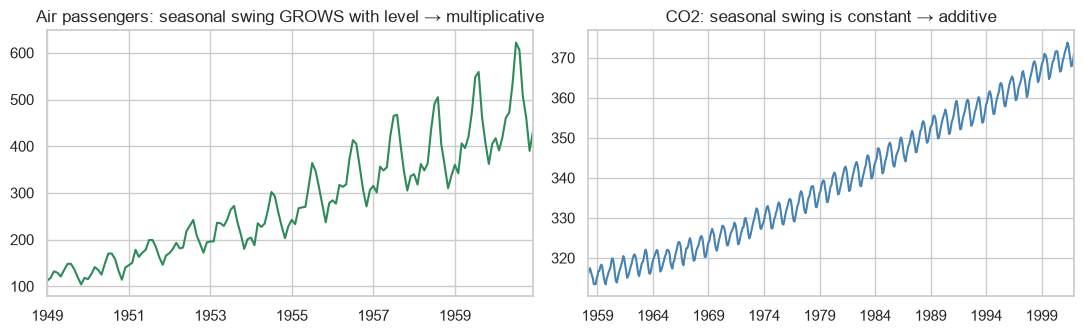

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
air.plot(ax=axes[0], color="seagreen")
axes[0].set_title("Air passengers: seasonal swing GROWS with level → multiplicative")

co2_data.plot(ax=axes[1], color="steelblue")
axes[1].set_title("CO2: seasonal swing is constant → additive")

for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()


## 3.3 Classical decomposition with `seasonal_decompose`

`statsmodels.tsa.seasonal.seasonal_decompose` performs the textbook
moving-average-based decomposition. It is fast and easy to read but assumes
the seasonal shape does not change over time.


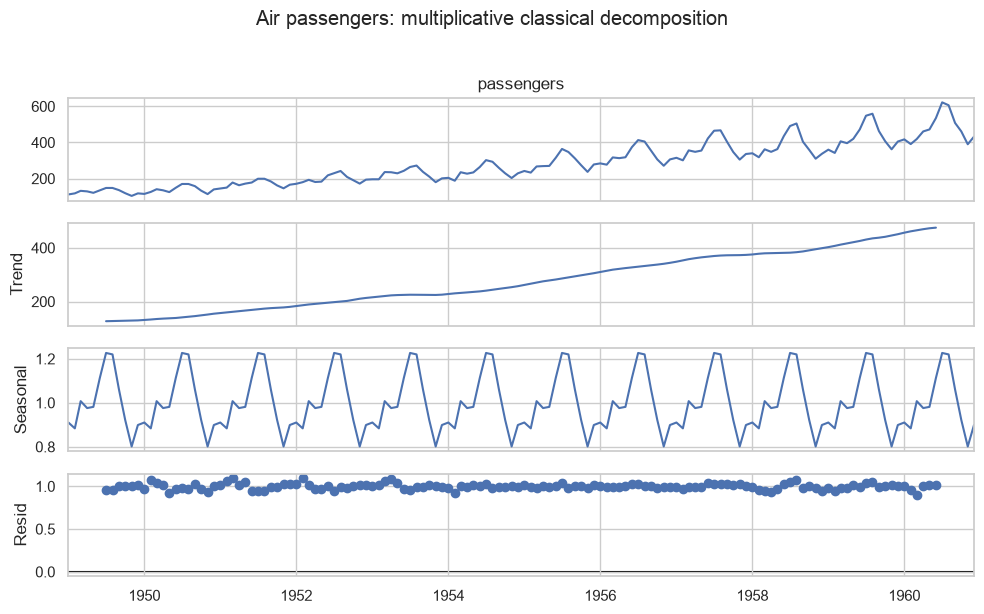

In [8]:
# Air passengers: multiplicative model, period = 12 months.
air_decomp = seasonal_decompose(air, model="multiplicative", period=12)
fig = air_decomp.plot()
fig.set_size_inches(10, 6)
fig.suptitle("Air passengers: multiplicative classical decomposition", y=1.02)
plt.tight_layout()
plt.show()


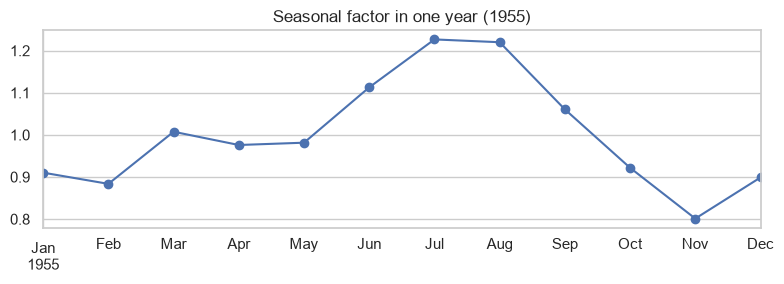

In [10]:
fig, ax = plt.subplots(figsize=(8, 3))
air_decomp.seasonal["1955"].plot(ax=ax, marker="o")
ax.set_title("Seasonal factor in one year (1955)")
plt.tight_layout()
plt.show()

Read the four panels top-to-bottom:

1. **observed**: the original series.
2. **trend**: a centred moving average; first/last few months are `NaN`.
3. **seasonal**: the repeating monthly factor (for multiplicative, ≈1 means
   "average month", >1 means "above-average month").
4. **resid**: what is left after dividing out trend × seasonal. A good
   decomposition leaves residuals that look like random noise.


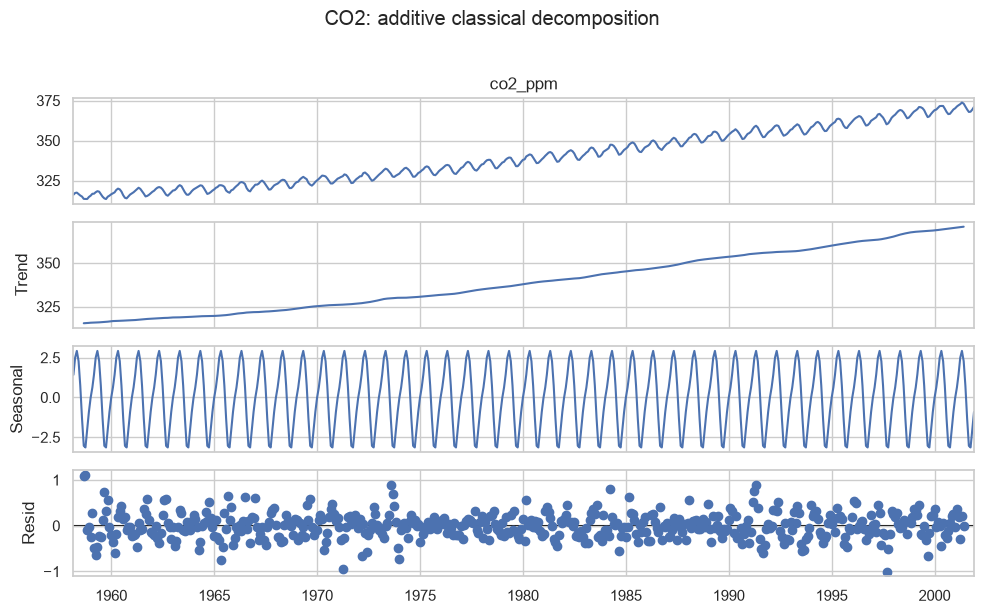

In [9]:
# CO2: additive model.
co2_decomp = seasonal_decompose(co2_data, model="additive", period=12)
fig = co2_decomp.plot()
fig.set_size_inches(10, 6)
fig.suptitle("CO2: additive classical decomposition", y=1.02)
plt.tight_layout()
plt.show()


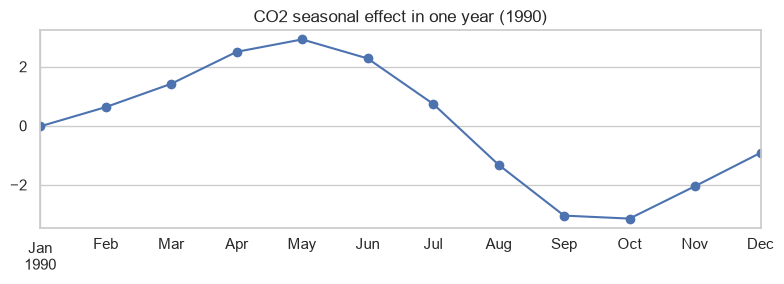

In [11]:
fig, ax = plt.subplots(figsize=(8, 3))
co2_decomp.seasonal["1990"].plot(ax=ax, marker="o")
ax.set_title("CO2 seasonal effect in one year (1990)")
plt.tight_layout()
plt.show()

## 3.4 STL: a more robust decomposition

**STL** (Seasonal-Trend decomposition using Loess) handles two things the
classical method does not:

- the seasonal shape may **drift slowly** over time, and
- it is **robust to outliers** when run in "robust" mode.

STL is additive, to use it on a multiplicative series, take logs first
(`np.log(y)`), decompose, and exponentiate when you need original units.


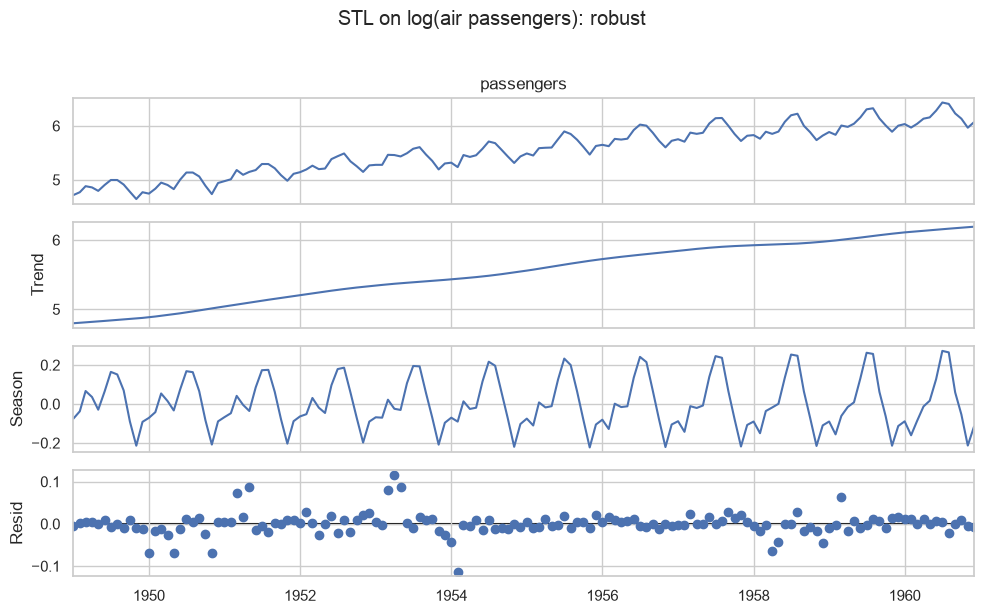

In [12]:
# STL on log(air) is equivalent to a multiplicative decomposition on air.
log_air = np.log(air)
stl_result = STL(log_air, period=12, robust=True).fit()

fig = stl_result.plot()
fig.set_size_inches(10, 6)
fig.suptitle("STL on log(air passengers): robust", y=1.02)
plt.tight_layout()
plt.show()


Compare with `seasonal_decompose` above:

- The STL **trend** is smoother and defined at the endpoints too (no `NaN`).
- The **seasonal** band visibly evolves, peaks get a little wider in the
  later years.
- The **residual** spikes during 1958 are easier to spot because STL did
  not let outliers bend the trend toward them.


## 3.5 Moving averages: the simplest smoother

A **moving average** replaces each observation with the mean of itself and
its $k$ neighbours. Larger windows smooth more aggressively but also blur
real features and shift recent points toward the past.

Three useful windows for monthly data:

- **3-month**: keeps short-term wiggles, removes one-off spikes.
- **12-month**: averages over a full year → almost-pure trend.
- **24-month**: over-smooths; trend only.


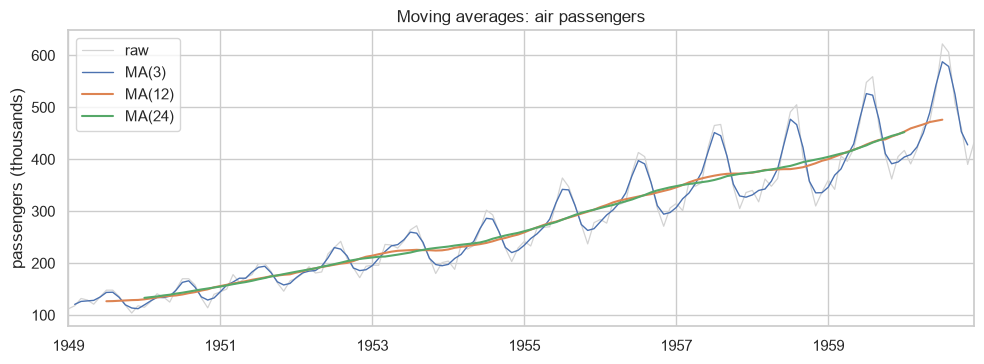

In [13]:
ma_3 = air.rolling(window=3, center=True).mean()
ma_12 = air.rolling(window=12, center=True).mean()
ma_24 = air.rolling(window=24, center=True).mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
air.plot(ax=ax, color="lightgrey", linewidth=0.9, label="raw")
ma_3.plot(ax=ax, label="MA(3)", linewidth=1.0)
ma_12.plot(ax=ax, label="MA(12)", linewidth=1.5)
ma_24.plot(ax=ax, label="MA(24)", linewidth=1.5)
ax.set_title("Moving averages: air passengers")
ax.set_ylabel("passengers (thousands)")
ax.legend()
plt.tight_layout()
plt.show()


The MA(12) line is the *centred 12-month moving average*, exactly the same
"trend" curve `seasonal_decompose` computed earlier. That is not a
coincidence: classical decomposition **is** a moving-average-based method.


## 3.6 Simple exponential smoothing: a first taste

A moving average gives every observation inside the window equal weight.
**Simple exponential smoothing (SES)** gives recent observations *more*
weight, controlled by a single parameter $\alpha \in (0, 1]$:

$$\hat{y}_{t+1|t} = \alpha \, y_t + (1 - \alpha) \, \hat{y}_{t|t-1}$$

- $\alpha$ close to 1 → almost only the last observation matters.
- $\alpha$ close to 0 → the smoothed value barely changes.

SES is *only* appropriate for series **without** a clear trend or seasonality,
so we apply it to the residual component of the CO2 decomposition rather
than to a raw series. Forecasting series **with** trend and seasonality is
notebook 5.


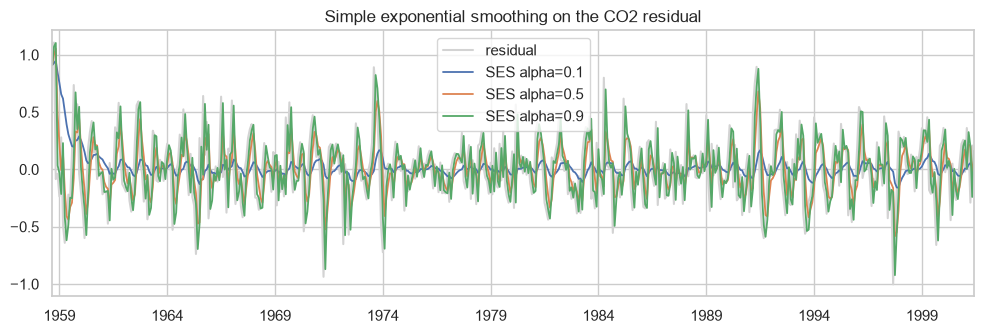

In [14]:
# Decompose CO2 and isolate the residual (de-trended + de-seasonalised).
co2_resid = seasonal_decompose(co2_data, model="additive", period=12).resid.dropna()

# Fit SES with three different alphas.
alphas = [0.1, 0.5, 0.9]
fits = {a: SimpleExpSmoothing(co2_resid, initialization_method="estimated")
        .fit(smoothing_level=a, optimized=False)
        for a in alphas}

fig, ax = plt.subplots(figsize=(10, 3.5))
co2_resid.plot(ax=ax, color="lightgrey", label="residual")
for a, fit in fits.items():
    fit.fittedvalues.plot(ax=ax, label=f"SES alpha={a}", linewidth=1.3)
ax.set_title("Simple exponential smoothing on the CO2 residual")
ax.legend()
plt.tight_layout()
plt.show()


With $\alpha = 0.1$ the smoothed line barely reacts, it is essentially a
slow moving average. With $\alpha = 0.9$ it tracks the residual almost
perfectly, which is the same as *barely smoothing at all*. The sweet spot
depends on how much you trust each individual observation.


## Exercises

**Exercise 3.1**: *Additive or multiplicative?*
Load the *Beer production* series with
`get_rdataset("ausbeer", package="fpp2").data` and plot it. Does the
seasonal swing grow with the level? Justify your choice of additive or
multiplicative decomposition in one or two sentences, then run
`seasonal_decompose` with that choice.

*Hint:* `ausbeer` is quarterly, so `period=4`.

**Exercise 3.2**: *STL vs classical.*
Run **both** `seasonal_decompose` (`model='additive'`) and
`STL(...)` on the CO2 series. Plot the two **trend** panels on the same
axes. Where do they differ, and which one would you trust at the endpoints
of the series?

**Exercise 3.3**: *Moving-average window size.*
For the CO2 series, plot moving averages with windows 3, 12, and 24.
Which window best reveals the *trend* without showing seasonality?
Why do you think so? *(No code beyond `rolling().mean()` needed.)*

**Exercise 3.4 (stretch)**: *Manual SES.*
Implement simple exponential smoothing in 5 lines of pure pandas:
`s = pd.Series(index=y.index); s.iloc[0] = y.iloc[0]; for t in range(1, len(y)): s.iloc[t] = alpha * y.iloc[t-1] + (1 - alpha) * s.iloc[t-1]`.
Compare your output against `statsmodels` `SimpleExpSmoothing` for
$\alpha = 0.3$ on the CO2 residual. Why are the first few values different?


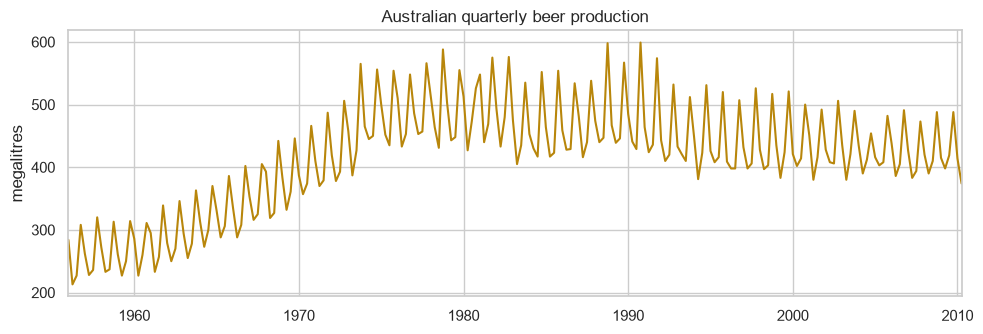

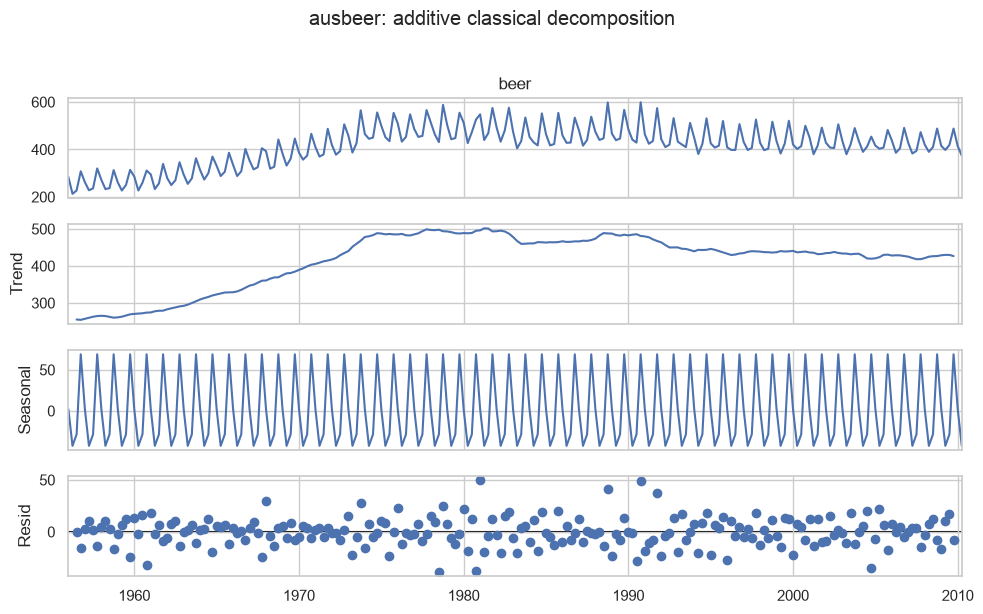

In [15]:
ausbeer_raw = get_rdataset("ausbeer", package="fpp2").data
ausbeer = ausbeer_raw["value"].dropna().reset_index(drop=True)
ausbeer.index = pd.period_range(start="1956Q1", periods=len(ausbeer), freq="Q").to_timestamp()
ausbeer.name = "beer"

fig, ax = plt.subplots(figsize=(10, 3.5))
ausbeer.plot(ax=ax, color="darkgoldenrod")
ax.set_title("Australian quarterly beer production")
ax.set_ylabel("megalitres")
plt.tight_layout()
plt.show()

beer_decomp = seasonal_decompose(ausbeer, model="additive", period=4)
fig = beer_decomp.plot()
fig.set_size_inches(10, 6)
fig.suptitle("ausbeer: additive classical decomposition", y=1.02)
plt.tight_layout()
plt.show()

**Exercise 3.1: additive or multiplicative?**

The seasonal swing does **not** grow with the level, so an **additive** decomposition is the right choice. Over the first ten years (1956 to 1965) the average level is about 282 megalitres with a yearly swing of about 94; over the last ten years (1999 to 2008) the level has risen to about 430 (+52%) while the swing is still about 99 (+5%). A multiplicative series would have shown the swing widening by about the same 50%.

The trend is not one-directional: it rises steeply until the mid-1970s, stays flat at roughly 480 to 500 until about 1990, then declines slowly to about 420. Production peaks in Q4 (October to December, the start of summer and Christmas in the Southern Hemisphere; mean 485) and is lowest in Q2 (mean 373).

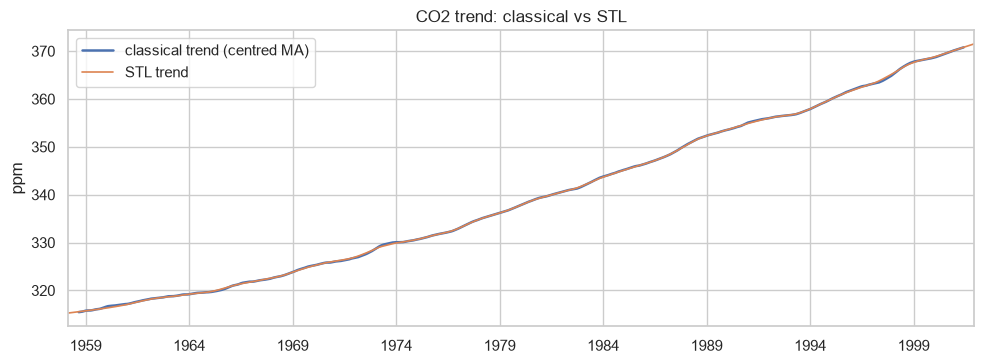

NaN in classical trend: 12
NaN in STL trend      : 0
max gap where both exist: 0.352


In [16]:
co2_add = seasonal_decompose(co2_data, model="additive", period=12)
co2_stl = STL(co2_data, period=12, robust=True).fit()

fig, ax = plt.subplots(figsize=(10, 3.8))
co2_add.trend.plot(ax=ax, label="classical trend (centred MA)", linewidth=1.8)
co2_stl.trend.plot(ax=ax, label="STL trend", linewidth=1.2)
ax.set_title("CO2 trend: classical vs STL")
ax.set_ylabel("ppm")
ax.legend()
plt.tight_layout()
plt.show()

print("NaN in classical trend:", co2_add.trend.isna().sum())
print("NaN in STL trend      :", co2_stl.trend.isna().sum())
print("max gap where both exist:", (co2_add.trend - co2_stl.trend).abs().max().round(3))

**Exercise 3.2: classical vs STL trend on CO2**

Through the interior the two trends are practically identical: the largest gap where both exist is 0.352 ppm and the mean gap is 0.067 ppm, about 0.1% of the level. They differ at the **endpoints**: the classical trend is a centred 12-month moving average, so it has 12 NaN values (the first and last six months), while STL's loess smoothing runs to the boundary and has none. At the endpoints I would use **STL**, because it is the only one that returns a value there, but with care: with neighbours on only one side its last estimates are less certain and can change when new data arrives (the end-point problem, which is why official seasonally adjusted figures get revised).

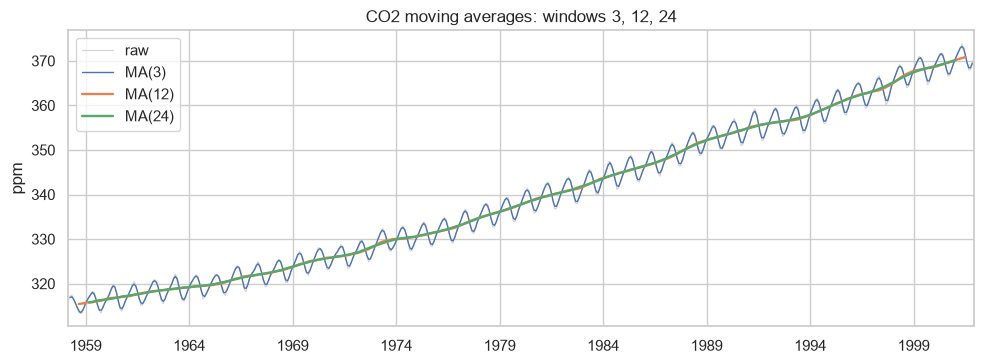

MA( 3): leftover wiggle vs STL trend = 1.824 ppm, NaN = 2
MA(12): leftover wiggle vs STL trend = 0.106 ppm, NaN = 11
MA(24): leftover wiggle vs STL trend = 0.085 ppm, NaN = 23


In [17]:
fig, ax = plt.subplots(figsize=(10, 3.8))
co2_data.plot(ax=ax, color="lightgrey", linewidth=0.8, label="raw")
co2_data.rolling(3, center=True).mean().plot(ax=ax, label="MA(3)", linewidth=1.0)
co2_data.rolling(12, center=True).mean().plot(ax=ax, label="MA(12)", linewidth=1.7)
co2_data.rolling(24, center=True).mean().plot(ax=ax, label="MA(24)", linewidth=1.7)
ax.set_title("CO2 moving averages: windows 3, 12, 24")
ax.set_ylabel("ppm")
ax.legend()
plt.tight_layout()
plt.show()

stl_trend = STL(co2_data, period=12, robust=True).fit().trend
for w in [3, 12, 24]:
    ma = co2_data.rolling(w, center=True).mean()
    wiggle = (ma - stl_trend).std()
    print(f"MA({w:2d}): leftover wiggle vs STL trend = {wiggle:.3f} ppm, NaN = {ma.isna().sum()}")

**Exercise 3.3: moving-average window size on CO2**

**MA(12)** best reveals the trend without seasonality. A 12-month window spans exactly one full seasonal cycle, so the within-year rise and fall cancel out. Measured as the standard deviation of the gap to the STL trend, the leftover wiggle is 1.824 ppm for MA(3), which still follows the seasonal zigzag, 0.106 ppm for MA(12), about 17 times smaller, and 0.085 ppm for MA(24). MA(24) is only slightly smoother but loses 23 months at the edges instead of 11, about one more year of the most recent data, and over-smooths real changes in the trend. So 12 is the natural choice: the smallest window that covers one complete season.

---

*Hyndman, R.J. & Athanasopoulos, G. (2021), Forecasting: Principles and
Practice (3rd ed.), Chapters 3 (decomposition) and 8 (exponential
smoothing). <https://otexts.com/fpp3/>*
